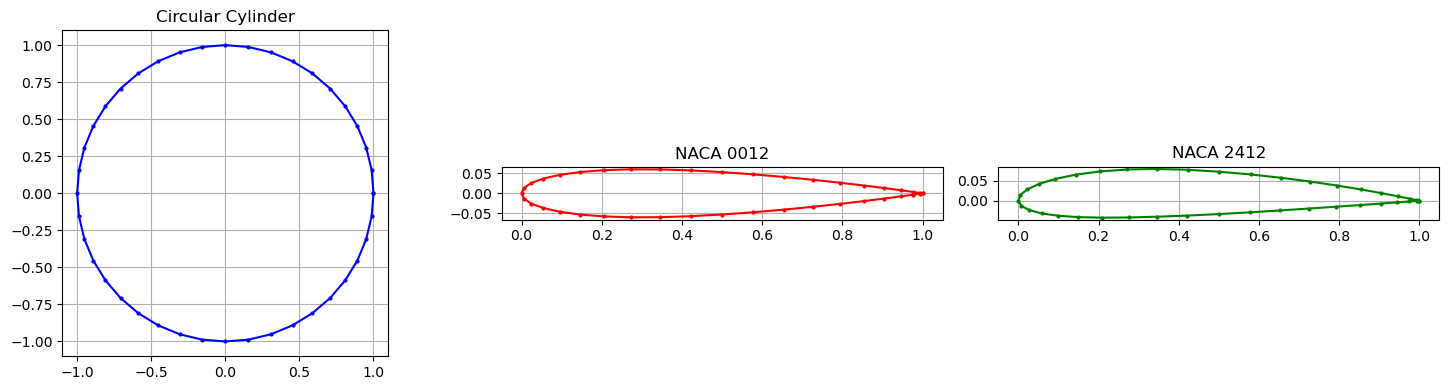

Geometry generation completed
--------------------------------
Number of panels: 40
Number of control points: 40
First panel length: 0.0062
First panel angle: 184.4256
First beta angle: 269.4256


In [1]:

# Vortex Panel Method - Geometry Generation

import numpy as np
import matplotlib.pyplot as plt


# 1. Numerical output formatting


def fmt(value, digits=4):
    value = float(value)

    if abs(value) < 0.5 * 10**(-digits):
        return "0"

    return f"{value:.{digits}f}".rstrip("0").rstrip(".")



# 2. Calculate panel geometry


def panel_geometry(XB, YB):

    dX = np.diff(XB)
    dY = np.diff(YB)

    # Panel length
    S = np.hypot(dX, dY)

    # Panel orientation angle
    phi = np.mod(np.arctan2(dY, dX), 2*np.pi)

    # Control point coordinates
    XC = 0.5 * (XB[:-1] + XB[1:])
    YC = 0.5 * (YB[:-1] + YB[1:])

    return XC, YC, S, phi



# 3. Calculate beta angle


def beta_angle(phi, alpha):

    beta = phi + np.pi/2 - alpha

    return beta


# 4. Generate circular cylinder coordinates


def cylinder_boundary_points(N, R=1.0):

    theta = np.linspace(0, -2*np.pi, N+1)

    XB = R * np.cos(theta)
    YB = R * np.sin(theta)

    return XB, YB



# 5. Generate NACA four-digit airfoil coordinates


def naca4_boundary_points(code, N, spacing='cosine'):

    if len(code) != 4 or not code.isdigit():
        raise ValueError("Enter a valid four-digit NACA code")

    if N < 4 or N % 2 != 0:
        raise ValueError("N must be an even number of at least 4")

    # Read NACA parameters
    m = int(code[0]) / 100
    p = int(code[1]) / 10
    t = int(code[2:]) / 100

    # Chordwise coordinate distribution
    n_side = N // 2

    if spacing == 'cosine':

        theta = np.linspace(0, np.pi, n_side+1)
        x = 0.5 * (1 - np.cos(theta))

    elif spacing == 'uniform':

        x = np.linspace(0, 1, n_side+1)

    else:

        raise ValueError("Spacing must be cosine or uniform")

    # Thickness distribution
    yt = 5*t*(
        0.2969*np.sqrt(x)
        - 0.1260*x
        - 0.3516*x**2
        + 0.2843*x**3
        - 0.1036*x**4
    )

    # Mean camber line
    yc = np.zeros_like(x)
    dyc_dx = np.zeros_like(x)

    if m != 0:

        for i in range(len(x)):

            if x[i] < p:

                yc[i] = (m/p**2) * (
                    2*p*x[i] - x[i]**2
                )

                dyc_dx[i] = (
                    2*m/p**2
                ) * (p-x[i])

            else:

                yc[i] = (m/(1-p)**2) * (
                    (1-2*p) + 2*p*x[i] - x[i]**2
                )

                dyc_dx[i] = (
                    2*m/(1-p)**2
                ) * (p-x[i])

    # Camber line angle
    theta_c = np.arctan(dyc_dx)

    # Upper surface coordinates
    xu = x - yt*np.sin(theta_c)
    yu = yc + yt*np.cos(theta_c)

    # Lower surface coordinates
    xl = x + yt*np.sin(theta_c)
    yl = yc - yt*np.cos(theta_c)

    # Arrange coordinates clockwise:
    # Trailing edge -> Lower surface -> Leading edge
    # -> Upper surface -> Trailing edge

    XB = np.concatenate((xl[::-1], xu[1:]))
    YB = np.concatenate((yl[::-1], yu[1:]))

    return XB, YB



# 6. Test the geometry functions


N = 40

# Cylinder
XB_cyl, YB_cyl = cylinder_boundary_points(N)

# NACA 0012
XB_0012, YB_0012 = naca4_boundary_points(
    '0012', N, spacing='cosine'
)

# NACA 2412
XB_2412, YB_2412 = naca4_boundary_points(
    '2412', N, spacing='cosine'
)



# 7. Plot generated geometries


fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].plot(XB_cyl, YB_cyl, 'b-o', markersize=2)
ax[0].set_title('Circular Cylinder')
ax[0].set_aspect('equal')
ax[0].grid()

ax[1].plot(XB_0012, YB_0012, 'r-o', markersize=2)
ax[1].set_title('NACA 0012')
ax[1].set_aspect('equal')
ax[1].grid()

ax[2].plot(XB_2412, YB_2412, 'g-o', markersize=2)
ax[2].set_title('NACA 2412')
ax[2].set_aspect('equal')
ax[2].grid()

plt.tight_layout()
plt.show()



# 8. Check panel geometry


XC, YC, S, phi = panel_geometry(
    XB_2412, YB_2412
)

alpha = np.radians(5)

beta = beta_angle(phi, alpha)

print("Geometry generation completed")
print("--------------------------------")
print("Number of panels:", len(S))
print("Number of control points:", len(XC))
print("First panel length:", fmt(S[0]))
print("First panel angle:", fmt(np.degrees(phi[0])))
print("First beta angle:", fmt(np.degrees(beta[0])))


In [2]:

from numpy.polynomial.legendre import leggauss


def compute_JK(XB, YB, XC, YC, phi):

    N = len(XC)

    J = np.zeros((N, N))
    K = np.zeros((N, N))

    # Gauss-Legendre integration points
    points, weights = leggauss(40)

    S = np.hypot(np.diff(XB), np.diff(YB))

    for i in range(N):

        # Normal and tangential directions
        nx = -np.sin(phi[i])
        ny = np.cos(phi[i])

        tx = np.cos(phi[i])
        ty = np.sin(phi[i])

        for j in range(N):

            # Self-influence: principal value
            if i == j:
                continue

            dx = XB[j+1] - XB[j]
            dy = YB[j+1] - YB[j]
            Sj = S[j]

            # Integration points along panel j
            s = 0.5 * Sj * (points + 1)
            w = 0.5 * Sj * weights

            xq = XB[j] + s * dx / Sj
            yq = YB[j] + s * dy / Sj

            # Distance from the vortex element to control point i
            rx = XC[i] - xq
            ry = YC[i] - yq

            r2 = rx**2 + ry**2

            # Induced velocity due to a unit vortex element
            u = -ry / (2 * np.pi * r2)
            v = rx / (2 * np.pi * r2)

            u_ind = np.sum(w * u)
            v_ind = np.sum(w * v)

            # Resolve velocity into normal and tangential components
            J[i, j] = u_ind * nx + v_ind * ny
            K[i, j] = u_ind * tx + v_ind * ty

    return J, K


# Calculate influence coefficients for NACA 2412
XC, YC, S, phi = panel_geometry(XB_2412, YB_2412)

J, K = compute_JK(XB_2412, YB_2412, XC, YC, phi)

print("Constant-strength influence coefficients")
print("-----------------------------------------")
print("Number of panels:", len(S))
print("J matrix size:", J.shape)
print("K matrix size:", K.shape)
print("J[0, 1]:", fmt(J[0, 1]))
print("K[0, 1]:", fmt(K[0, 1]))


Constant-strength influence coefficients
-----------------------------------------
Number of panels: 40
J matrix size: (40, 40)
K matrix size: (40, 40)
J[0, 1]: -0.3085
K[0, 1]: -0.0001


Constant-strength vortex panel solution
----------------------------------------
Number of panels: 40
Angle of attack: 5 degrees
Lift coefficient: 0.8371
Minimum Cp: -5.2839
Maximum Cp: 0.9998
First vortex strength: 0.9112
Last vortex strength: -0.9112
Kutta condition: 0
Maximum normal velocity error: 0.0002


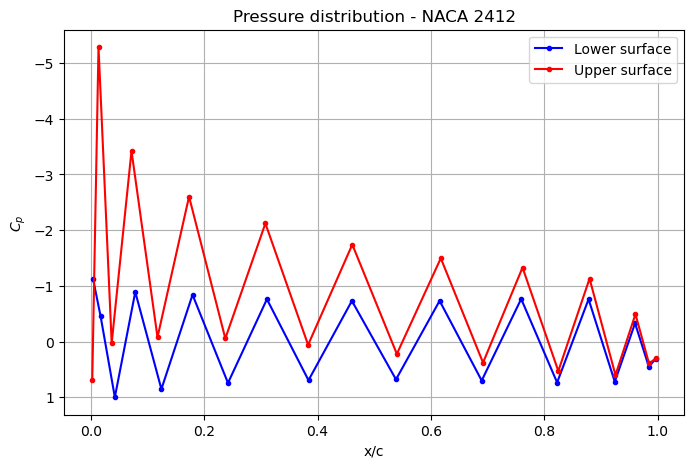

In [3]:

def vortex_panel_method_0(XB, YB, alpha, V_inf=1, chord=1):

    # Panel geometry
    XC, YC, S, phi = panel_geometry(XB, YB)
    N = len(S)

    # Influence coefficient matrices
    J = np.zeros((N, N))
    K = np.zeros((N, N))

    # Calculate the influence of each panel
    for i in range(N):

        nx = -np.sin(phi[i])
        ny = np.cos(phi[i])

        tx = np.cos(phi[i])
        ty = np.sin(phi[i])

        for j in range(N):

            if i == j:
                continue

            # Transform control point into local panel coordinates
            dx = XC[i] - XB[j]
            dy = YC[i] - YB[j]

            x = dx*np.cos(phi[j]) + dy*np.sin(phi[j])
            y = -dx*np.sin(phi[j]) + dy*np.cos(phi[j])

            Sj = S[j]

            # Analytical velocity induced by a constant vortex panel
            theta1 = np.arctan2(-x, abs(y))
            theta2 = np.arctan2(Sj-x, abs(y))

            u_local = -np.sign(y)*(theta2-theta1)/(2*np.pi)

            r1 = x**2 + y**2
            r2 = (x-Sj)**2 + y**2

            v_local = np.log(r1/r2)/(4*np.pi)

            # Transform velocity into global coordinates
            u = u_local*np.cos(phi[j]) - v_local*np.sin(phi[j])
            v = u_local*np.sin(phi[j]) + v_local*np.cos(phi[j])

            # Normal and tangential influence coefficients
            J[i, j] = u*nx + v*ny
            K[i, j] = u*tx + v*ty

    # Freestream velocity components
    Vx = V_inf*np.cos(alpha)
    Vy = V_inf*np.sin(alpha)

    # Outward normal components
    nx = -np.sin(phi)
    ny = np.cos(phi)

    # No-penetration boundary condition
    RHS = -(Vx*nx + Vy*ny)

    # Apply the Kutta condition
    # gamma[0] + gamma[-1] = 0

    A = np.zeros((N, N-1))

    A[:, 0] = J[:, 0] - J[:, -1]
    A[:, 1:] = J[:, 1:-1]

    # Solve for the vortex strengths
    gamma_reduced, residuals, rank, singular_values = np.linalg.lstsq(
        A, RHS, rcond=None
    )

    # Recover all panel strengths
    gamma = np.zeros(N)

    gamma[0] = gamma_reduced[0]
    gamma[1:-1] = gamma_reduced[1:]
    gamma[-1] = -gamma[0]

    # Freestream tangential velocity
    Vt_inf = Vx*np.cos(phi) + Vy*np.sin(phi)

    # Tangential velocity on the outer surface
    Vt = Vt_inf + K @ gamma - 0.5*gamma

    # Pressure coefficient
    Cp = 1 - (Vt/V_inf)**2

    # Check the boundary condition
    normal_velocity = Vx*nx + Vy*ny + J @ gamma

    max_normal_error = np.max(np.abs(normal_velocity))

    # Lift coefficient from pressure integration
    Cl = -np.sum(Cp*ny*S)/chord

    return gamma, Vt, Cp, Cl, max_normal_error


# NACA 2412 at 5 degrees angle of attack
alpha = np.radians(5)

gamma, Vt, Cp, Cl, normal_error = vortex_panel_method_0(
    XB_2412,
    YB_2412,
    alpha,
    V_inf=1,
    chord=1
)

print("Constant-strength vortex panel solution")
print("----------------------------------------")
print("Number of panels:", len(gamma))
print("Angle of attack:", fmt(np.degrees(alpha)), "degrees")
print("Lift coefficient:", fmt(Cl))
print("Minimum Cp:", fmt(np.min(Cp)))
print("Maximum Cp:", fmt(np.max(Cp)))
print("First vortex strength:", fmt(gamma[0]))
print("Last vortex strength:", fmt(gamma[-1]))
print("Kutta condition:", fmt(gamma[0] + gamma[-1]))
print("Maximum normal velocity error:", fmt(normal_error))


# Separate upper and lower surface pressure distributions
mid = len(Cp)//2

plt.figure(figsize=(8, 5))

plt.plot(
    XC[:mid], Cp[:mid],
    'bo-', markersize=3, label='Lower surface'
)

plt.plot(
    XC[mid:], Cp[mid:],
    'ro-', markersize=3, label='Upper surface'
)

plt.gca().invert_yaxis()
plt.xlabel("x/c")
plt.ylabel("$C_p$")
plt.title("Pressure distribution - NACA 2412")
plt.legend()
plt.grid()
plt.show()
